In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm


We shall next study Gaussian process regression. The most canonical example of a Gaussian process is the Brownian Motion. Here is how it can be simulated. 
## Brownian Motion
$B_t$ is Brownian motion. The following algorithm simulates Brownian Motion on $[0, M]$ for some fixed $M$ (e.g.,  $M = 65$). 


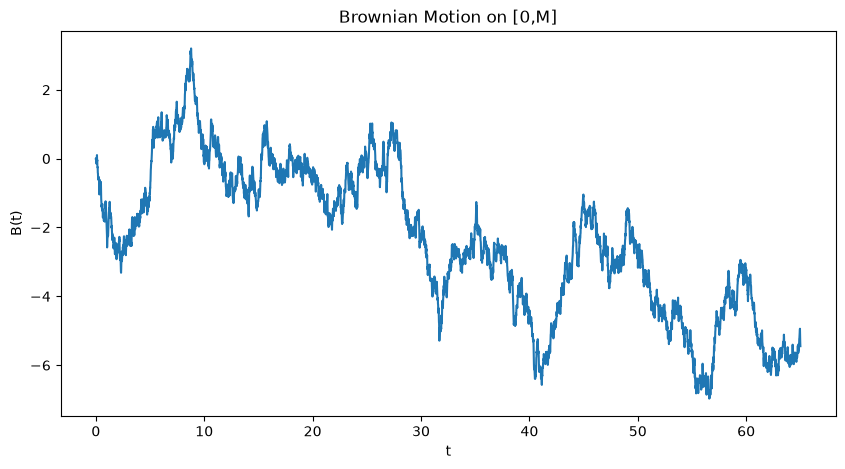

In [2]:
M = 65         # time horizon
N = 5000        # number of grid points
dt = M / N       # step size

t = np.linspace(0, M, N+1)

# generate increments
increments = np.sqrt(dt) * np.random.randn(N)

# Brownian path
B = np.zeros(N+1)
B[1:] = np.cumsum(increments)

plt.figure(figsize=(10, 5))
plt.plot(t, B)
plt.xlabel("t")
plt.ylabel("B(t)")
plt.title("Brownian Motion on [0,M]")
plt.show()



In the plot above, successive values are joined by straight lines. We can also plot by assuming that the value is constant in between successive values. This is done below.


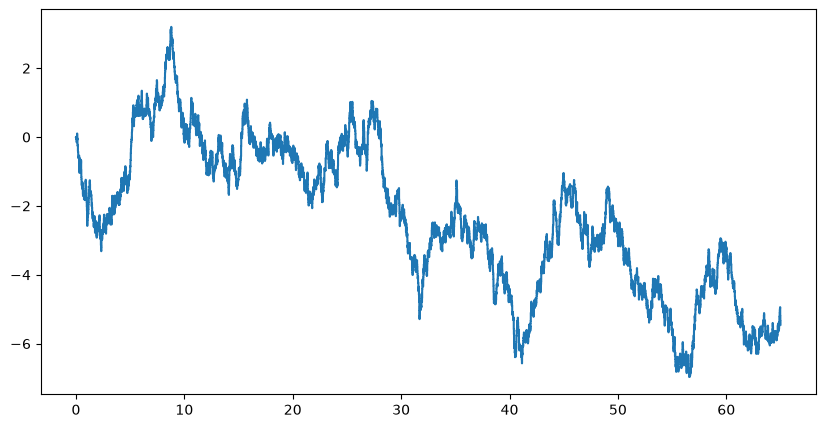

In [3]:
plt.figure(figsize=(10, 5))
plt.step(t, B, where="post")
plt.show()


When $N$ is large, we cannot spot any differences between the above two plots (the differences are much more apparent when $N$ is small). 
Note here that $t_i = i M/N$ for $i = 0, \dots, N$. In the second plot (plt.step) above, what we are plotting is: 
\begin{align*}
   \sum_{i=1}^N \alpha_i I\{t \geq i M/N \}
\end{align*}
where $\alpha_i := B(t_i) - B(t_{i-1}) \overset{\text{i.i.d}}{\sim} N(0, M/N)$. We are thus using the approximation: 
\begin{align*}
   B(t) \approx \sum_{i=1}^N \alpha_i I \{t \geq i M/N \}. 
\end{align*}
The implies the following ReLU approximation to Integrated Brownian Motion. 
\begin{align*}
   I(t) = \int_0^t B(s) ds \approx \sum_{i=1}^N \alpha_i \int_0^t I\{s \geq iM/N\} ds = \sum_{i=1}^N \alpha_i (t - iM/N)_+
\end{align*}



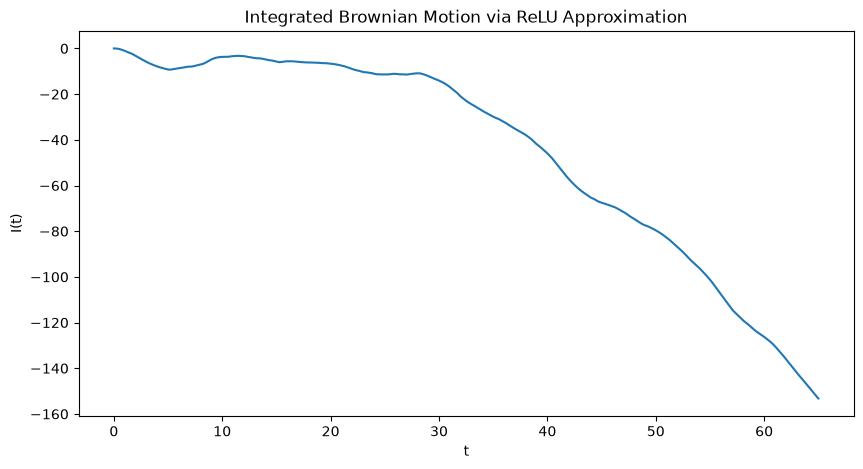

In [4]:
# Integrated Brownian Motion using the ReLU representation

knots = t[1:]  # iM/N, i = 1,...,N
alpha = increments

I_relu = np.zeros(N + 1)

for i in range(N):
    I_relu += alpha[i] * np.maximum(t - knots[i], 0)

plt.figure(figsize=(10, 5))
plt.plot(t, I_relu)
plt.xlabel("t")
plt.ylabel("I(t)")
plt.title("Integrated Brownian Motion via ReLU Approximation")
plt.show()


Now we will sample IBM curves with a linear drift. 


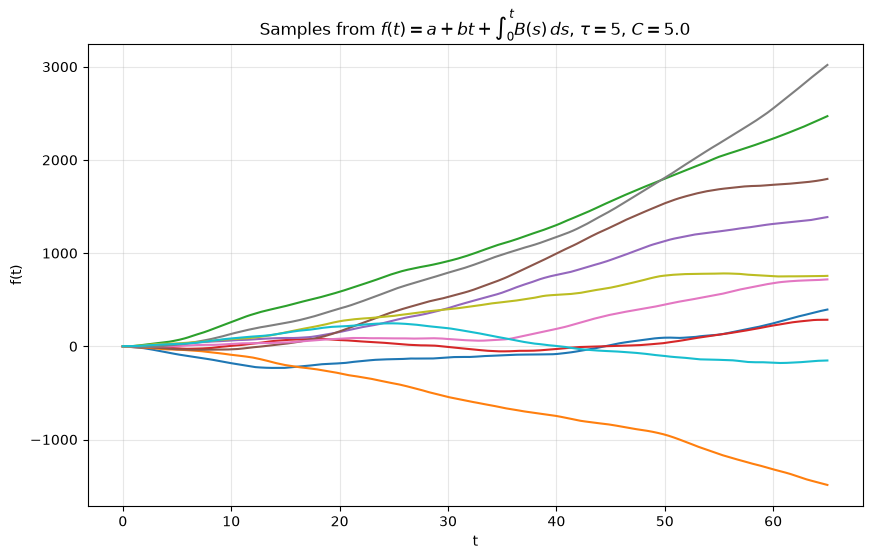

In [5]:
# Samples from f(t) = a + b t + Integrated Brownian Motion

tau = 5          # IBM scale
C = 5.0          # variance of intercept and slope
n_samples = 10

plt.figure(figsize=(10, 6))

for _ in range(n_samples):

    # Brownian increments
    increments = tau * np.sqrt(dt) * np.random.randn(N)

    # Brownian motion
    B = np.zeros(N + 1)
    B[1:] = np.cumsum(increments)

    # Integrated Brownian motion
    I = np.zeros(N + 1)
    I[1:] = np.cumsum(B[:-1] * dt)

    # Random linear part
    a = np.random.normal(0, np.sqrt(C))
    b = np.random.normal(0, np.sqrt(C))

    # Full sample path
    f = a + b * t + I

    plt.plot(t, f, lw=1.5)

plt.xlabel("t")
plt.ylabel("f(t)")
plt.title(fr"Samples from $f(t)=a+bt+\int_0^t B(s)\,ds$, $\tau={tau}$, $C={C}$")
plt.grid(alpha=0.3)
plt.show()
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Interpolation with Gaussian Processes
We are solving the following problem. Given the values of a function $f : [0, 1] \rightarrow \R$ at fixed points $0 \leq x_1 < \dots < x_n \leq 1$, what can we say about $f(x)$ for some $x$ that is distinct from $x_1, \dots, x_n$?


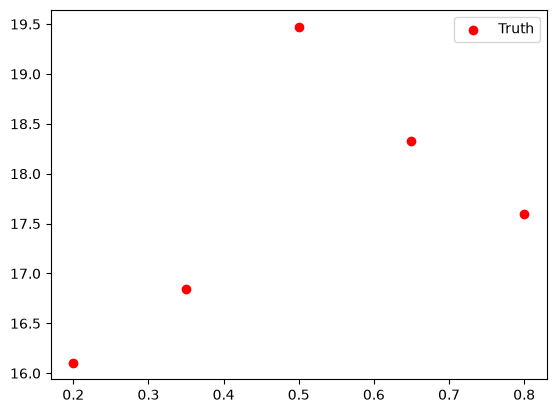

In [6]:
#Consider the following smooth function: 
def smoothfun(x):
    ans = np.sin(15*x) + 15*np.exp(-(x ** 3)/2) + 0.5*((x - 0.5) ** 2) + 5 * np.log(x + 0.1) + 7
    return ans

#Here is another example of a function: 
#def smoothfun(x):
#    ans = (np.sin(15*x) + 0.6*np.sin(60*x) + 0.4*np.sin(120*x) + 15*np.exp(-(x**3)/2) + 0.5*((x-0.5)**2) + 5*np.log(x+0.1) + 7)
#    return ans

#We observe this function at the following points: 
n = 5
xx = np.linspace(0, 1, n) #these are equally spaced points
xx = np.linspace(0.2, 0.8, n)
#xx = np.sort(np.random.rand(n)) #these are unequally spaced points

#these are the values of the function at the observed points, which we will treat as our data
truth = np.array([smoothfun(x) for x in xx])
y = truth
#Below we plot the scatter plot of the observed data
plt.scatter(xx, truth, label = 'Truth', color = 'red')
plt.legend()
plt.show()


## Interpolation using Brownian Motion
We will use the Brownian motion prior: $f(x) = \beta_0 + \tau B(x)$ with $\beta_0 \sim N(0, C)$ and $B(x)$ is Brownian motion. We will compute the posterior mean of $f(x)$ using the formula: $\mathbf{k}^TK^{-1} (f(x_1), \dots, f(x_n))^T$, where the kernel is given by $K(u, v) = C + \tau^2 \min(u, v)$. $K$ is the matrix whose $(i, j)$-th entry is $K(x_i, x_j)$, and $\mathbf{k}$  is the vector whose $i$-th element is $K(x, x_i)$. This calculation will require specification of $\tau$ and $C$ ($C$ can be large constant). The value of $\tau$ does not affect the posterior mean (as can be easily checked from the code below). We still choose a reasonable value of $\tau$ using the observation that: 
\begin{align*}
   f(x_i) - f(x_{i-1}) = \tau \left(B(x_i) - B(x_{i-1}) \right) \sim N(0, \tau^2 (x_i - x_{i-1}))
\end{align*}
This means that
\begin{align*}
    \mathbb{E} \frac{1}{n-1}\sum_{i=2}^n \left[ \frac{1}{x_{i} - x_{i-1}} \left( f(x_i) - f(x_{i-1}) \right)^2 \right] = \tau^2. 
\end{align*}
This gives a decent estimate of $\tau$ which we compute as follows. 


In [7]:
#crude estimate of tau
dx = np.diff(xx)
dy = np.diff(y)

tau2_hat = np.mean((dy**2) / dx)
tau_hat = np.sqrt(tau2_hat)

print(tau_hat)


3.943306705404783


With this value of $\tau$ and a large value of $C$, we compute the posterior mean of $f(x)$ as follows. We also compute the posterior variance (and the posterior standard deviation). Instead of computing these at a fixed value of $x$, we compute them over a grid of values of $x$. 


In [8]:
# hyperparameters
tau = tau_hat
C = 1000

# kernel
def kernel_BM(s,t):
    return C + tau**2 * min(s,t)

# covariance matrix
K = np.array([[kernel_BM(xi,xj) for xj in xx] for xi in xx])
Kinv = np.linalg.inv(K)

# grid for prediction
grid = np.linspace(0,1,200)

post_mean_bm = np.zeros(len(grid))
post_var_bm = np.zeros(len(grid))

for i,x in enumerate(grid):

    kstar = np.array([kernel_BM(x,xi) for xi in xx])
    kxx = kernel_BM(x,x)

    post_mean_bm[i] = kstar @ Kinv @ truth
    post_var_bm[i] = kxx - kstar @ Kinv @ kstar

post_sd_bm = np.sqrt(post_var_bm)


Below we plot the posterior means of the grid points (as well as twice the posterior standard deviations). The posterior standard deviations give an idea of the uncertainty present in the mean estimates. 


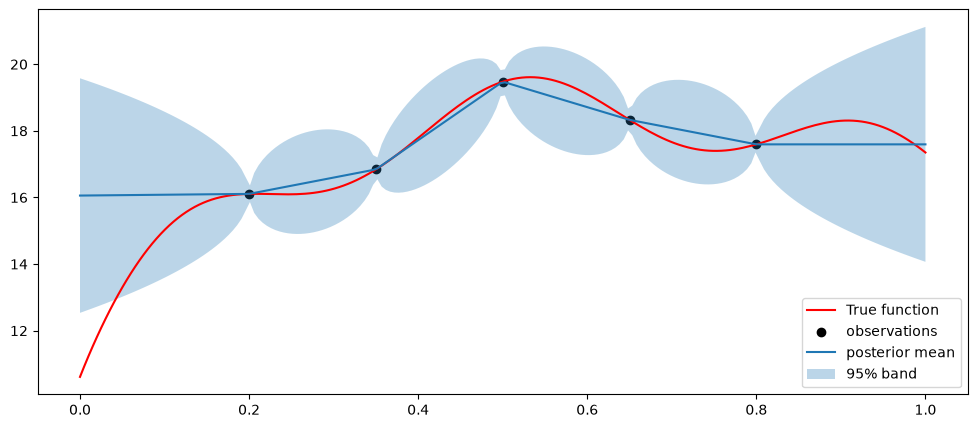

In [9]:
truth_grid = np.array([smoothfun(x) for x in grid])
plt.figure(figsize=(12,5))
plt.plot(grid, truth_grid, label="True function", color="red")
plt.scatter(xx,y,color="black",label="observations")

plt.plot(grid, post_mean_bm, label="posterior mean")

plt.fill_between(grid,
                 post_mean_bm-2*post_sd_bm,
                 post_mean_bm+2*post_sd_bm,
                 alpha=0.3,
                 label="95% band")

plt.legend()
plt.show()


Below we only plot the posterior mean. 


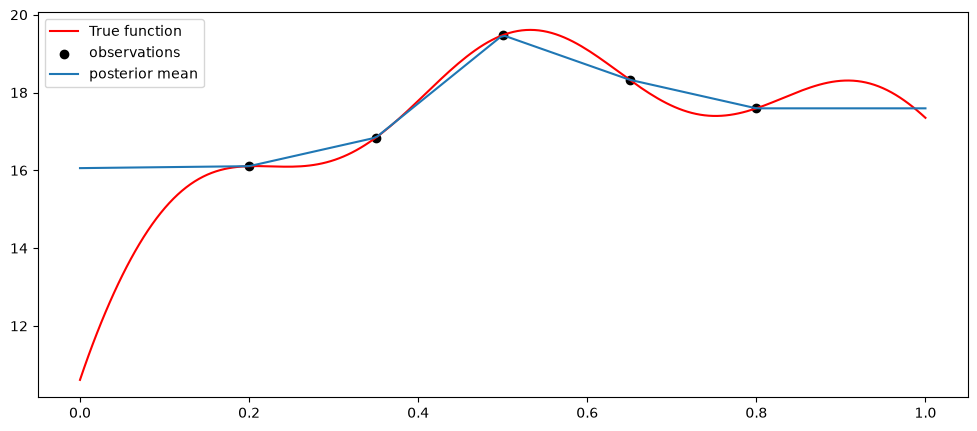

In [10]:
#Only plotting the posterior mean: 
plt.figure(figsize=(12,5))
plt.plot(grid, truth_grid, label="True function", color="red")
plt.scatter(xx,y,color="black",label="observations")
plt.plot(grid, post_mean_bm, label="posterior mean")
plt.legend()
plt.show()


Clearly the posterior mean linearly interpolates between the data. Go back and changes $x_1, \dots, x_n$ so they are random points in $[0, 1]$ which allows us to see that estimates beyond $[x_1, x_n]$ are constant. 
## Interpolation using Integrated Brownian Motion
Now we use the prior $f(x) = \beta_0 + \beta_1 x + \tau I(x)$ where $I(x)$ is integrated Brownian motion. The code for computing the posterior mean of $f(x)$ is same as below; the only change is in the formula for $K(u, v)$. 


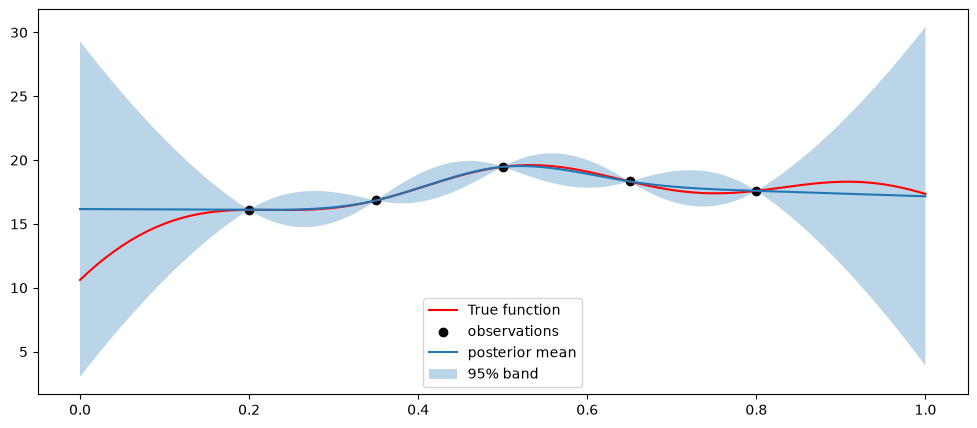

In [11]:
# hyperparameters
tau = 100.0
C = 100000.0

# covariance of integrated Brownian motion
def kernel_IBM(s, t):
    m = min(s, t)
    M = max(s, t)
    return (m**2) * (3*M - m) / 6.0

# full kernel for f(x) = beta0 + beta1 x + tau I(x)
def kernel_f(s, t):
    return C + C*s*t + tau**2 * kernel_IBM(s, t)

# covariance matrix
K = np.array([[kernel_f(xi, xj) for xj in xx] for xi in xx])

# tiny jitter just for numerical stability
K = K + 1e-10 * np.eye(len(xx))

Kinv = np.linalg.inv(K)

# grid for prediction
grid = np.linspace(0, 1, 200)

post_mean_ibm = np.zeros(len(grid))
post_var_ibm = np.zeros(len(grid))

for i, x in enumerate(grid):
    kstar = np.array([kernel_f(x, xi) for xi in xx])
    kxx = kernel_f(x, x)

    post_mean_ibm[i] = kstar @ Kinv @ truth
    post_var_ibm[i] = kxx - kstar @ Kinv @ kstar

# guard against tiny negative values from floating point error
post_var_ibm = np.maximum(post_var_ibm, 0)
post_sd_ibm = np.sqrt(post_var_ibm)
truth_grid = np.array([smoothfun(x) for x in grid])
plt.figure(figsize=(12,5))
plt.plot(grid, truth_grid, label="True function", color="red")
plt.scatter(xx,y,color="black",label="observations")

plt.plot(grid, post_mean_ibm, label="posterior mean")

plt.fill_between(grid,
                 post_mean_ibm-2*post_sd_ibm,
                 post_mean_ibm+2*post_sd_ibm,
                 alpha=0.3,
                 label="95% band")

plt.legend()
plt.show()


It is interesting that the posterior variance is narrower between the observed points and becomes wider as we go away from the observations and close to the boundary. 


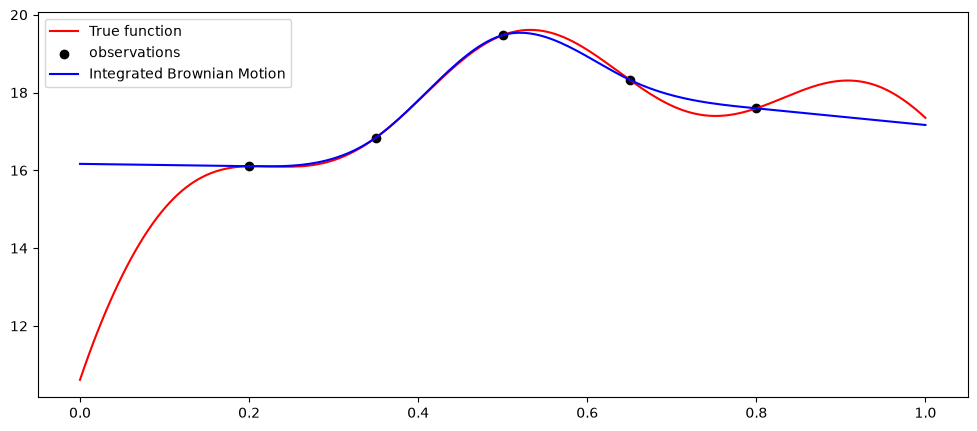

In [12]:
#Only plotting the posterior mean: 
plt.figure(figsize=(12,5))
plt.plot(grid, truth_grid, label="True function", color="red")
plt.scatter(xx,y,color="black",label="observations")
#plt.plot(grid, post_mean_bm, label = 'Brownian Motion', color = 'black')
plt.plot(grid, post_mean_ibm, label = 'Integrated Brownian Motion', color = 'blue')
plt.legend()
plt.show()
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm


# Gaussian Process Regression
Consider again the wages dataset that we have been using for the past few lectures. This simple dataset, which comes from the introductory statistics textbook "Statistical Sleuth" by Ramsey and Schafer,  contains weekly wages in 1987 for a sample of 25437 males between the ages of 18 and 70 who worked full-time along with their years of education, years of experience, indicator variable for whether they worked near a city, and a code for the region in the US where they worked.


In [13]:
#Load the dataset wagedata.csv
dt = pd.read_csv("wagedata.csv")
print(dt.head(10))
print(dt.shape)


      Region   MetropolitanStatus  Exper  Educ  WeeklyEarnings
0      South  NotMetropolitanArea      8    12          859.71
1    Midwest     MetropolitanArea     30    12          786.73
2       West     MetropolitanArea     31    14         1424.50
3       West     MetropolitanArea     17    16          959.16
4       West     MetropolitanArea      6    12          154.32
5    Midwest     MetropolitanArea     24    17          282.19
6  Northeast     MetropolitanArea     14    12          444.44
7  Northeast     MetropolitanArea     28    12          451.09
8      South     MetropolitanArea     40    12          490.27
9      South     MetropolitanArea      7    16          493.83
(25437, 5)


We want to fit a regression model with logarithm of weekly earnings as the response variable:
\begin{align*}
   y = \log \left( \text{weekly earnings} \right)
\end{align*}
and years of experience as the covariate: 
\begin{align*}
   x = \text{Exper} = \text{Years of Experience}.
\end{align*}
The following is the scatter plot between $y$ and $x$. 


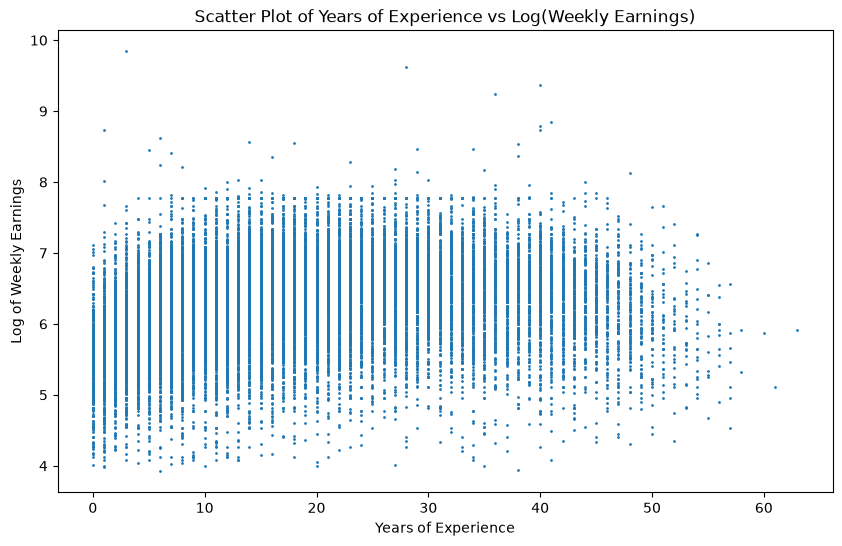

Using a random sample of n = 500 observations out of 25437.


In [14]:
import numpy as np
y = np.log(dt['WeeklyEarnings'])
x = dt['Exper'].to_numpy()
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(x, y, s=1)
plt.xlabel('Years of Experience')
plt.ylabel('Log of Weekly Earnings')
plt.title('Scatter Plot of Years of Experience vs Log(Weekly Earnings)')
plt.show()

# A reproducible simple random sample of 500 observations (without replacement).
random_seed = 42
sample_size = 500
dt_small = dt.sample(n=sample_size, random_state=random_seed)
# dt_small = dt  # Uncomment to analyze the full dataset (much more expensive).
y = np.log(dt_small['WeeklyEarnings']).to_numpy()
x = dt_small['Exper'].to_numpy()
n = len(y)
print(f'Using a random sample of n = {n} observations out of {len(dt)}.')


**Why do we take a random sample of 500 observations?** The original wage dataset contains many more observations. Gaussian process regression below uses the kernel matrix $K_I=(k_I(x_i,x_j))_{i,j=1}^n$ and must solve linear systems involving $A_\gamma=I_n+\gamma^2K_I$, an **$n\times n$ matrix**. Standard dense matrix factorizations require $O(n^3)$ arithmetic and $O(n^2)$ storage, which become costly for the full dataset. We therefore take a **reproducible random sample of 500 observations** (seed 42) to demonstrate the method at manageable computational cost. In fact, $A_\gamma$ is positive definite for every $\gamma$ because of the identity term; the challenge is the **computational cost of inversion/solving**, not lack of mathematical invertibility.

The rest of the GP regression analysis below uses this subsample.


We want to consider the model: 
\begin{align*}
   y = f(x) + \epsilon 
\end{align*}
where $\epsilon \sim N(0, \sigma^2)$. 
## Integrated Brownian Motion Prior

For $f$, we want to use the integrated Brownian motion plus a linear term prior: 
\begin{align*}
   f(x) = \beta_0 + \beta_1 x + \tau I(x) 
\end{align*}
where $I(x)$ is integrated Brownian motion and $\beta_0, \beta_1$ are $N(0, C)$ for a large $C$. 

This is a Gaussian Process model with mean function zero and covariance kernel: 
\begin{align*}
   K(u, v) = C(1 + uv) + \tau^2 \frac{(\min(u, v))^2}{6} \left(3 \max(u, v) - \min(u, v)\right).  
\end{align*}
If $\gamma := \tau/\sigma$ is fixed, then the posterior mean of $f$ at a test point $u$ is given by: 
\begin{align*}
   \hat{f}(u) := (1, u) \left(X^T A_{\gamma}^{-1} X \right)^{-1} X^T A_{\gamma}^{-1} y + \gamma^2 k_I(u)^T \left(A_{\gamma}^{-1} - A_{\gamma}^{-1} X (X^T A_{\gamma}^{-1} X)^{-1} X^T A_{\gamma}^{-1} \right) y
\end{align*}
where $X$ is the $n \times 2$ design matrix of the usual linear regression (with columns of ones and $x_1, \dots, x_n$), 
\begin{align*}
   k_I(u) := (k_I(u, x_1), \dots, k_I(u, x_n))^T ~~~ \text{and} ~~~ K_I := (K_I(x_i, x_j))_{n \times n},
\end{align*}
and
\begin{align*}
    A_{\gamma} = I_{n \times n} + \gamma^2 K_I. 
\end{align*}
Note that the posterior mean only depends on $\gamma = \tau/\sigma$ and not on $\tau$ and $\sigma$ individually. 

The following code computes the posterior mean of $f(u)$ given a fixed value of $\gamma$. In the code, we are using the notation: 
\begin{align*}
P = A_{\gamma}^{-1} - A_{\gamma}^{-1} X (X^T A_{\gamma}^{-1} X)^{-1} X^T A_{\gamma}^{-1}.
\end{align*}
and
\begin{align*}
  \alpha = \left(X^T A_{\gamma}^{-1} X \right)^{-1} X^T A_{\gamma}^{-1} y. 
\end{align*}


In [ ]:
#gamma = 0.027 #some arbitrary value
#gamma = 0.1
#gamma = .0001
gamma = 2
#gamma = 10
X = np.column_stack((np.ones(n), x)) #usual X matrix for linear regression

def K_I(u, v):
    minuv = min(u, v)
    maxuv = max(u, v)
    return (minuv**2 / 6.0) * (3*maxuv - minuv)

K_ibm = np.array([[K_I(xi, xj) for xj in x] for xi in x])

# grid
M = np.max(x)
grid_f = np.linspace(0, M, 100) #number of points u where the posterior mean is calculated
kvec  = np.array([[K_I(u, xi) for xi in x] for u in grid_f])

# A_gamma
A_gamma = np.eye(n) + gamma**2 * K_ibm
A_gamma_inv = np.linalg.inv(A_gamma)

#the X^T A_gamma^-1 X and its inverse
XtAinvX = X.T @ A_gamma_inv @ X
XtAinvX_inv = np.linalg.inv(XtAinvX)

# the matrix P (defined above)
P = A_gamma_inv - A_gamma_inv @ X @ XtAinvX_inv @ X.T @ A_gamma_inv

# Offset term:
alpha = XtAinvX_inv  @ X.T @ A_gamma_inv @ y

# all the vectors (1, u) stacked together for all u in grid_f
H = np.column_stack((np.ones(len(grid_f)), grid_f))

# posterior mean
post_mean = H @ alpha + gamma**2 * kvec @ (P @ y)

# Conditional-on-gamma posterior covariance for the latent regression curve.
# With diffuse (flat-limit) intercept/slope prior, we account for their uncertainty.
kstarstar_diag = np.array([K_I(u, u) for u in grid_f])
D = H - gamma**2 * kvec @ A_gamma_inv @ X
latent_cov_diag = (
    gamma**2 * kstarstar_diag
    - gamma**4 * np.einsum('ij,ij->i', kvec @ A_gamma_inv, kvec)
    + np.einsum('ij,ij->i', D @ XtAinvX_inv, D)
)
latent_cov_diag = np.maximum(latent_cov_diag, 0.0)

# Integrate out sigma^2 with p(sigma) proportional to 1/sigma.
# sigma^2 | gamma, y ~ Inverse-Gamma((n-2)/2, S_gamma/2).
# The latent f(u) marginally follows a Student-t with df=n-2.
from scipy.stats import t as student_t
S_gamma = float(y @ P @ y)
df = n - 2
t_crit = student_t.ppf(0.975, df)
posterior_t_scale = np.sqrt((S_gamma / df) * latent_cov_diag)
credible_lower = post_mean - t_crit * posterior_t_scale
credible_upper = post_mean + t_crit * posterior_t_scale


The biggest computational bottleneck in the code above involves the inversion of the $n \times n$ matrix $A_{\gamma}$. When $n$ is large, the code can be quite slow. For example, try the code on the full dataset with $n \approx 25000$. 
Let us plot the posterior mean estimates on the data. 


The plot below displays the **posterior mean** and **95% pointwise Bayesian credible intervals** for the latent mean function $f(u)$, conditional on the displayed choice of $\gamma$. We integrate out the unknown noise variance $\sigma^2$ using the scale prior $p(\sigma)\propto 1/\sigma$, yielding a Student-$t$ posterior with $n-2$ degrees of freedom. Uncertainty about the intercept and slope is included in the band. These are **pointwise credible intervals**, not a simultaneous 95% credible band or prediction interval for a new noisy observation. Because $\gamma$ is fixed here, the intervals do **not** yet average over posterior uncertainty in $\gamma$.


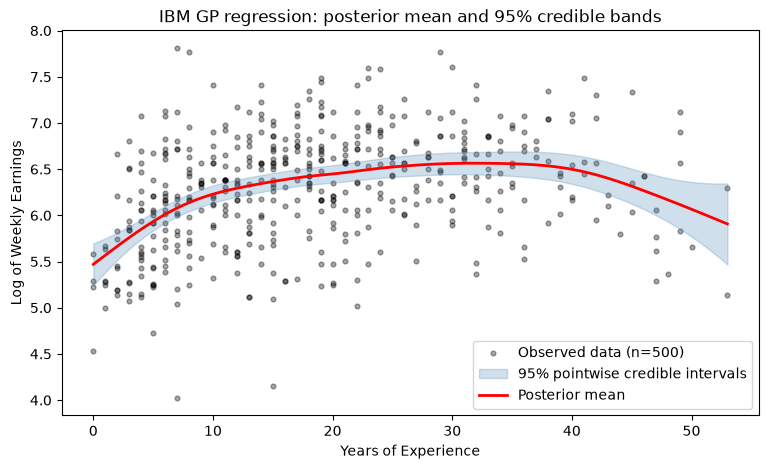

In [16]:
plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='black', s=12, alpha=0.35, label='Observed data (n=500)')
plt.fill_between(grid_f, credible_lower, credible_upper,
                 color='steelblue', alpha=0.25, label='95% pointwise credible intervals')
plt.plot(grid_f, post_mean, color='red', linewidth=2, label='Posterior mean')
plt.xlabel('Years of Experience')
plt.ylabel('Log of Weekly Earnings')
plt.title('IBM GP regression: posterior mean and 95% credible bands')
plt.legend()
plt.show()


The above seems a good fit to the data, capturing that the average log weekly income first increases and then decreases with experience. Go back and change gamma and see the resulting fit.  
Next we learn the values of $\gamma$ and $\sigma$. The marginal posterior of $\gamma$ is given by: 
\begin{align*}
   \text{posterior of } \gamma \propto \frac{p(\gamma) |A_{\gamma}|^{-1/2} |X^T A_{\gamma}^{-1} X|^{-1/2}}{\left(y^T \left[A_{\gamma}^{-1} - A_{\gamma}^{-1} X (X^T A_{\gamma}^{-1} X)^{-1} X^T A_{\gamma}^{-1} \right] y \right)^{(n/2)- 1}}.   
\end{align*}
where $p(\gamma)$ is the prior for $\gamma$ which we take:
\begin{align*}
    p(\gamma) \propto \frac{I\{\gamma_{\text{low}} \leq \gamma \leq \gamma_{\text{high}}\}}{\gamma}
\end{align*}
for two values $\gamma_{\text{low}}$ and $\gamma_{\text{high}}$ (roughly, $\gamma_{\text{low}}$ will be taken such that the posterior mean of $f$ gives the least squares line, and $\gamma_{\text{high}}$ will be taken such that the posterior mean of $f$ gives an overfitted curve). 


In [17]:
gamma_low = 0.0001
gamma_high = 10
grid_size = 2000
gamma_gr = np.logspace(np.log10(gamma_low), np.log10(gamma_high), grid_size)
logpost_gamma = np.zeros(len(gamma_gr))
Svals = np.zeros(len(gamma_gr))

for i in range(len(gamma_gr)):
    gamma = gamma_gr[i]
    A_gamma = np.eye(n) + gamma ** 2 * K_ibm
    A_gamma_inv = np.linalg.inv(A_gamma)
    XtAinvX = X.T @ A_gamma_inv @ X
    XtAinvX_inv = np.linalg.inv(XtAinvX)
    P = A_gamma_inv - A_gamma_inv @ X @ XtAinvX_inv @ X.T @ A_gamma_inv
    S = y.T @ P @ y
    Svals[i] = S
    sign1, logdetA = np.linalg.slogdet(A_gamma)
    sign2, logdetXtAinvX = np.linalg.slogdet(XtAinvX)
    logpost_gamma[i] = -np.log(gamma)-0.5*logdetA-0.5*logdetXtAinvX-(n/2 - 1)*np.log(S)
    #logpost_gamma[i] = -0.5*logdetA-0.5*logdetXtAinvX-(n/2 - 1)*np.log(S) #if we replace the 1/gamma prior with a flat prior, this will be the posterior of gamma
post_gamma = np.exp(logpost_gamma - np.max(logpost_gamma))
# correct for log grid spacing
post_gamma = post_gamma * gamma_gr
#normalization: 
post_gamma = post_gamma / np.sum(post_gamma)
postmean_gamma = np.sum(gamma_gr * post_gamma)
print(postmean_gamma)
print(1/(postmean_gamma**2))  # lambda = 1/gamma^2


0.027786012231468663
1295.231968187476


This posterior mean of $\gamma$ provides an automatic choice that can be used downstream to calculate the posterior mean of $f$.




## Posterior histograms of $\gamma$ and $\sigma$

We now visualize uncertainty in the smoothing parameter $\gamma$ and the noise standard deviation $\sigma$. The array `post_gamma` above already contains normalized posterior weights for the logarithmically spaced grid, including the grid-spacing correction. We use those weights directly to sample $\gamma$.

With the prior $p(\sigma)\propto 1/\sigma$ and a diffuse prior on the intercept and slope,
\[
\sigma^2\mid y,\gamma\sim\operatorname{InverseGamma}
\left(\frac{n-2}{2},\frac{S_\gamma}{2}\right),
\qquad S_\gamma=y^TP_\gamma y.
\]
The values of $S_\gamma$ have already been saved in `Svals`. Equivalently, the precision $1/\sigma^2$ has a Gamma distribution with shape $(n-2)/2$ and **rate** $S_\gamma/2$; NumPy uses a **scale**, so we pass $2/S_\gamma$.

First draw a grid index from `post_gamma`, then draw the precision conditional on that index, and transform it to $\sigma$. The resulting histogram of $\sigma$ averages over uncertainty in $\gamma$; it is not conditional on a single selected smoothing parameter. The histograms below show $\gamma$ and $\sigma$, not their logarithms or $\sigma^2$.

In [18]:
# Posterior draws using the existing IBM grid calculation
posterior_rng = np.random.default_rng(42)
n_posterior_draws = 20000

if n <= 2 or not np.all(np.isfinite(Svals)) or np.any(Svals <= 0):
    raise ValueError("Posterior sampling requires n > 2 and finite positive Svals.")
if not np.all(np.isfinite(post_gamma)) or np.any(post_gamma < 0):
    raise ValueError("The gamma posterior weights must be finite and nonnegative.")
if not np.isclose(np.sum(post_gamma), 1.0):
    raise ValueError("Run the gamma posterior normalization cell first.")

posterior_indices = posterior_rng.choice(
    len(gamma_gr), size=n_posterior_draws, p=post_gamma
)
gamma_samples = gamma_gr[posterior_indices]

# NumPy's Gamma distribution uses shape and scale (not rate).
precision_samples = posterior_rng.gamma(
    shape=(n - 2) / 2,
    scale=2.0 / Svals[posterior_indices]
)
sigma_samples = 1.0 / np.sqrt(precision_samples)


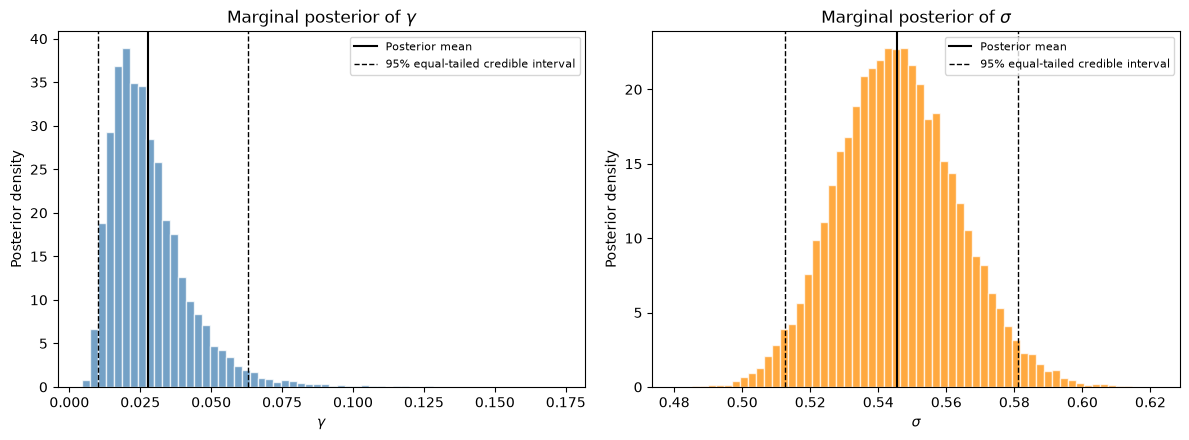

gamma: mean = 0.027813, median = 0.0249, 95% credible interval = [0.010198, 0.062936]
sigma: mean = 0.54557, median = 0.54507, 95% credible interval = [0.5125, 0.58116]


In [19]:
# Marginal posterior histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, samples, symbol, color in zip(
    axes,
    [gamma_samples, sigma_samples],
    [r"\gamma", r"\sigma"],
    ["steelblue", "darkorange"]
):
    lower, median, upper = np.quantile(samples, [0.025, 0.5, 0.975])
    ax.hist(samples, bins=60, density=True, color=color,
            alpha=0.75, edgecolor="white")
    ax.axvline(np.mean(samples), color="black", linewidth=1.5,
               label="Posterior mean")
    ax.axvline(lower, color="black", linestyle="--", linewidth=1,
               label="95% equal-tailed credible interval")
    ax.axvline(upper, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel(fr"${symbol}$")
    ax.set_ylabel("Posterior density")
    ax.set_title(fr"Marginal posterior of ${symbol}$")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

for name, samples in [("gamma", gamma_samples), ("sigma", sigma_samples)]:
    lower, median, upper = np.quantile(samples, [0.025, 0.5, 0.975])
    print(f"{name}: mean = {np.mean(samples):.5g}, median = {median:.5g}, "
          f"95% credible interval = [{lower:.5g}, {upper:.5g}]")


The $\gamma$ histogram shows which amounts of smoothing are supported by the data. The $\sigma$ histogram describes uncertainty in the noise standard deviation on the log-weekly-earnings scale. The dashed lines mark equal-tailed 95% credible intervals; the solid line marks the posterior mean. These are Monte Carlo summaries of the grid-based posterior.

The main takeaway is that Bayesian inference learns the smoothing and noise parameters from the data, without requiring cross-validation.

## Fully Bayesian regression curve: posterior sampling and credible bands

We now propagate uncertainty in **both** hyperparameters, rather than fixing $\gamma$ at a chosen value. For each posterior draw $(\gamma^{(s)},\sigma^{(s)})$ from the histograms above, sample the entire latent regression curve on `grid_f` from its conditional Gaussian posterior:

\[
 f(\text{grid}_f)\mid y,\gamma^{(s)},\sigma^{(s)}\sim
 N\bigl(m_{\gamma^{(s)}},\ (\sigma^{(s)})^2V_{\gamma^{(s)}}\bigr).
\]

Here $m_\gamma$ is the conditional GP posterior mean and $V_\gamma$ includes uncertainty about the intercept and slope under the diffuse-prior limit. We plot the **average of the sampled curves**, together with their **pointwise 2.5% and 97.5% posterior quantiles**. These intervals include uncertainty in $\gamma$, $\sigma$, and $f$ conditional on those parameters. They are pointwise credible intervals for the latent mean function, not simultaneous bands or predictive intervals for future noisy observations.

To keep this class demonstration quick, we use a subset of the hyperparameter posterior draws for the curve simulation and diagonalize the $n\times n$ IBM kernel matrix only once.

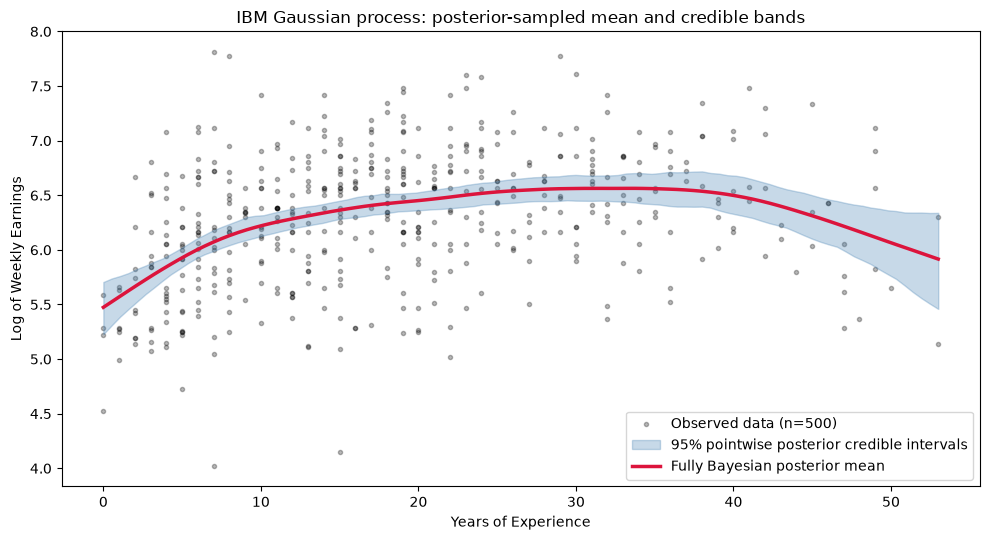

In [20]:
# Fully Bayesian posterior sampling of the latent function on grid_f.
# gamma_samples and sigma_samples were obtained above; they are *paired* draws.
# We use a reproducible subset to avoid repeatedly factoring large matrices.
n_curve_draws = 300
curve_rng = np.random.default_rng(2026)
chosen = curve_rng.choice(len(gamma_samples), size=n_curve_draws, replace=False)

# Eigen-decompose K_ibm once: (I + gamma^2 K_ibm)^(-1) is then inexpensive.
eigvals, eigvecs = np.linalg.eigh(K_ibm)
eigvals = np.maximum(eigvals, 0.0)  # remove tiny numerical negatives
UX = eigvecs.T @ X
Uy = eigvecs.T @ np.asarray(y)
Uk = eigvecs.T @ kvec.T  # n x number of prediction locations

# Prior covariance for the IBM component at the prediction locations.
G = len(grid_f)
Kgg = np.array([[K_I(u, v) for v in grid_f] for u in grid_f])
H = np.column_stack((np.ones(G), grid_f))

function_draws = np.empty((n_curve_draws, G))
for s, idx in enumerate(chosen):
    gam = float(gamma_samples[idx])
    sig = float(sigma_samples[idx])
    weight = 1.0 / (1.0 + gam**2 * eigvals)

    # A_gamma^{-1} applied to the necessary columns (without forming inverse).
    invX = eigvecs @ (weight[:, None] * UX)
    invy = eigvecs @ (weight * Uy)
    invk = eigvecs @ (weight[:, None] * Uk)  # n x G

    Q = X.T @ invX
    Qinv = np.linalg.inv(Q)  # only 2 x 2
    beta_mean = Qinv @ (X.T @ invy)
    correction = H - gam**2 * (kvec @ invX)
    mean_curve = H @ beta_mean + gam**2 * (kvec @ (invy - invX @ beta_mean))

    # Gaussian posterior covariance / sigma^2, including intercept/slope.
    V = (gam**2 * Kgg
         - gam**4 * (kvec @ invk)
         + correction @ Qinv @ correction.T)
    V = (V + V.T) / 2  # numerical symmetry

    # Draw jointly across the grid, retaining posterior dependence across x.
    jitter = 1e-9
    for attempt in range(8):
        try:
            L = np.linalg.cholesky(V + jitter * np.eye(G))
            break
        except np.linalg.LinAlgError:
            jitter *= 10
    else:
        raise np.linalg.LinAlgError("Unable to stabilize posterior covariance")
    function_draws[s] = mean_curve + sig * (L @ curve_rng.standard_normal(G))

fully_bayes_mean = function_draws.mean(axis=0)
fully_bayes_lower, fully_bayes_upper = np.quantile(
    function_draws, [0.025, 0.975], axis=0
)

plt.figure(figsize=(10, 5.5))
plt.scatter(x, y, s=9, alpha=0.28, color='black', label='Observed data (n=500)')
plt.fill_between(grid_f, fully_bayes_lower, fully_bayes_upper,
                 color='steelblue', alpha=0.3,
                 label='95% pointwise posterior credible intervals')
plt.plot(grid_f, fully_bayes_mean, color='crimson', linewidth=2.5,
         label='Fully Bayesian posterior mean')
plt.xlabel('Years of Experience')
plt.ylabel('Log of Weekly Earnings')
plt.title('IBM Gaussian process: posterior-sampled mean and credible bands')
plt.legend()
plt.tight_layout()
plt.show()
